<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Extrasomatic proportions with uncorrected vs. uRNA-corrected expression.
> - **Manuscript panels:** Fig. 5H, ED Fig. 7J
> - **Inputs:** Corrected zarr from `recompute_source_score_final_lambda05_decontaminated.py` and the uncorrected one
> - **Outputs:** Violin plots and comparison plots
> - **Environment / kernel:** `troutpy_updated`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# uRNA proportion per cell type -- corrected vs. uncorrected

Reproduces the per-cell-type extracellular (uRNA) proportion analysis from `6_computing_protrusion_proportions.ipynb` (`compute_and_extrasomatic_proportion` / violin+strip plot, one point per gene), run on both:
- **Uncorrected**: `data_annotated_lambda0.5.zarr` (production lambda=0.5 source score on raw counts)
- **Corrected**: `data_annotated_lambda0.5_decontaminated.zarr` (same lambda=0.5 source score, but computed on `troutpy.tl.subtract_local_urna_background`-corrected counts -- see `recompute_source_score_final_lambda05_decontaminated.py`)

plus direct comparison plots between the two.

In [1]:
import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import spatialdata as sd

matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

from troutpy import tl


## Load both datasets

In [2]:
data_dir = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k")
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/urna_proportion_corrected_vs_uncorrected")
saving_path.mkdir(parents=True, exist_ok=True)

print("Loading uncorrected (lambda=0.5, raw counts)...")
sdata_raw = sd.read_zarr(data_dir / "data_annotated_lambda0.5.zarr")

print("Loading corrected (lambda=0.5, decontaminated counts)...")
sdata_corr = sd.read_zarr(data_dir / "data_annotated_lambda0.5_decontaminated.zarr")

Loading uncorrected (lambda=0.5, raw counts)...


no parent found for <ome_zarr.reader.Label object at 0x7fa116c45c10>: None


no parent found for <ome_zarr.reader.Label object at 0x7fa116c45fa0>: None


Loading corrected (lambda=0.5, decontaminated counts)...


## `compute_and_extrasomatic_proportion`

Same tool function as in `6_computing_protrusion_proportions.ipynb`: per gene x cell type, `extracellular_proportion = extra / (extra + intra)`, where `extra` comes from the source-score contribution matrix and `intra` from the (raw or decontaminated) expression grouped by cell type.

In [3]:
def compute_and_extrasomatic_proportion(
    sdata,
    source_score_key="source_score",
    expr_key="table",
    xrna_key="xrna_metadata",
    layer_key="raw",
    output_key="extrasomatic_proportion_x_cell_type",
):
    sdata[expr_key].X = sdata[expr_key].layers[layer_key]
    sdata[expr_key].X = sdata[expr_key].X.toarray() if hasattr(sdata[expr_key].X, "toarray") else np.asarray(sdata[expr_key].X)
    expr = sdata[expr_key].to_df()
    cell_types = sdata[expr_key].obs["cell_type"]

    xrna_count = sdata[xrna_key].var["count"]
    contrib_df = sdata[source_score_key].to_df()
    contrib_df["gene"] = sdata[source_score_key].obs["gene"]

    contrib_matrix = contrib_df.groupby("gene").sum()
    contrib_matrix = contrib_matrix.T.groupby(level=0).sum().T

    genes_common = contrib_matrix.index.intersection(xrna_count.index)
    extra_matrix = contrib_matrix.loc[genes_common]

    grouped = expr.groupby(cell_types)
    intra_matrix = grouped.sum().T
    intra_mean_matrix = grouped.mean().T

    genes_final = extra_matrix.index.intersection(intra_matrix.index)
    celltypes_final = extra_matrix.columns.intersection(intra_matrix.columns)
    extra_matrix = extra_matrix.loc[genes_final, celltypes_final]
    intra_matrix = intra_matrix.loc[genes_final, celltypes_final]
    intra_mean_matrix = intra_mean_matrix.loc[genes_final, celltypes_final]

    extracellular_proportion = extra_matrix / (extra_matrix + intra_matrix)

    extrasomatic_ct = sc.AnnData(extracellular_proportion.transpose())
    extrasomatic_ct.obs["cell_type"] = extrasomatic_ct.obs.index
    extrasomatic_ct.layers["extra_expression"] = extra_matrix.transpose()
    extrasomatic_ct.layers["intra_expression"] = intra_matrix.transpose()
    extrasomatic_ct.layers["intra_mean_expression"] = intra_mean_matrix.transpose()
    sdata[output_key] = extrasomatic_ct
    return sdata


def extrasomatic_long_df(sdata, output_key="extrasomatic_proportion_x_cell_type", min_expr_mean=1.0, min_expr_frac=0.1):
    """Flatten the extrasomatic AnnData into a long (gene, cell_type, extracellular_proportion) table, filtered."""
    ext = sdata[output_key]
    extra = pd.DataFrame(ext.layers["extra_expression"].T, index=ext.var_names, columns=ext.obs_names)
    intra_mean = pd.DataFrame(ext.layers["intra_mean_expression"].T, index=ext.var_names, columns=ext.obs_names)
    prop = pd.DataFrame(ext.X.T, index=ext.var_names, columns=ext.obs_names)

    gene_filter = (intra_mean > min_expr_mean) & (intra_mean.div(intra_mean.sum(axis=1), axis=0) > min_expr_frac)

    rows = []
    for cell_type in extra.columns:
        filt = gene_filter[cell_type]
        p = prop[cell_type][filt].fillna(0)
        for gene, val in p.items():
            rows.append({"gene": gene, "cell_type": cell_type, "extracellular_proportion": val})
    return pd.DataFrame(rows)

In [4]:
compute_and_extrasomatic_proportion(sdata_raw, layer_key="raw")
compute_and_extrasomatic_proportion(sdata_corr, layer_key="decontaminated_density")

df_raw = extrasomatic_long_df(sdata_raw)
df_raw["condition"] = "uncorrected"
df_corr = extrasomatic_long_df(sdata_corr)
df_corr["condition"] = "corrected"

df_raw.to_csv(saving_path / "extrasomatic_proportion_uncorrected.csv", index=False)
df_corr.to_csv(saving_path / "extrasomatic_proportion_corrected.csv", index=False)
print(df_raw.shape, df_corr.shape)

(2560, 4) (2441, 4)


## Violin plots, one point per gene, per cell type

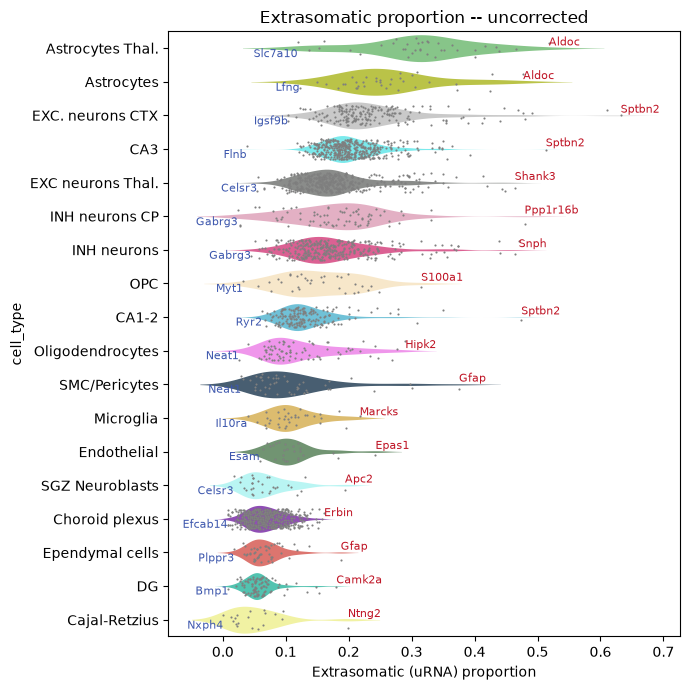

In [5]:
def get_celltype_colors(sdata):
    adata = sdata["table"]
    cats = adata.obs["cell_type"].astype("category").cat.categories
    if "cell_type_colors" in adata.uns:
        return dict(zip(cats, adata.uns["cell_type_colors"]))
    return None


coldict_raw = get_celltype_colors(sdata_raw)
coldict_corr = get_celltype_colors(sdata_corr)
# Same annotation -> same categories -> colors should agree; fall back to whichever is available.
coldict = coldict_raw or coldict_corr


def violin_by_celltype(df, title, filename, coldict, n_label=1):
    order_ct = df.groupby("cell_type")["extracellular_proportion"].mean().sort_values(ascending=False).index
    palette = [coldict[ct] for ct in order_ct] if coldict else None

    fig, ax = plt.subplots(figsize=(7, 7), dpi=100)
    sns.violinplot(data=df, y="cell_type", x="extracellular_proportion", order=order_ct,
                   palette=palette, alpha=0.8, linewidth=0, inner=None, ax=ax)
    sns.stripplot(data=df, y="cell_type", x="extracellular_proportion", color="gray",
                  s=1.5, order=order_ct, jitter=0.3, linewidth=0.01, ax=ax)

    # Top/bottom n gene labels per cell type, matching the convention in
    # 6_computing_protrusion_proportions.ipynb / the nucleiVScyto validation notebook.
    for cell_type in order_ct:
        df_sub = df[df["cell_type"] == cell_type]
        top_n = df_sub.nlargest(n_label, "extracellular_proportion")
        for _, row in top_n.iterrows():
            ax.text(row["extracellular_proportion"], cell_type, row["gene"],
                    color="#bf1324", fontsize=8, va="bottom", ha="left")
        bottom_n = df_sub.nsmallest(n_label, "extracellular_proportion")
        for _, row in bottom_n.iterrows():
            ax.text(row["extracellular_proportion"], cell_type, row["gene"],
                    color="#3d57ad", fontsize=8, va="top", ha="right")

    ax.set_xlabel("Extrasomatic (uRNA) proportion")
    ax.set_title(title)
    plt.tight_layout()
    fig.savefig(saving_path / filename, format="pdf", bbox_inches="tight")
    plt.show()
    return order_ct


order_ct_raw = violin_by_celltype(df_raw, "Extrasomatic proportion -- uncorrected", "violin_uncorrected.pdf", coldict)

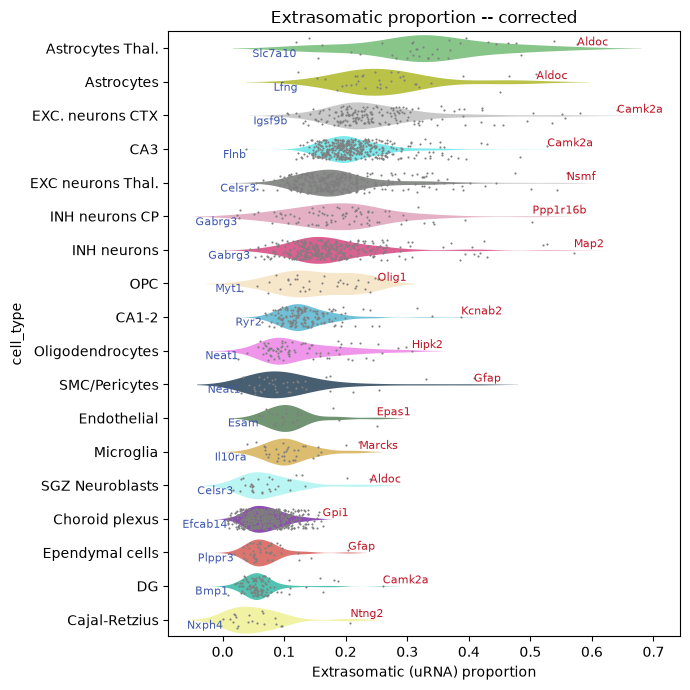

In [6]:
order_ct_corr = violin_by_celltype(df_corr, "Extrasomatic proportion -- corrected", "violin_corrected.pdf", coldict)

## Comparison: corrected vs. uncorrected

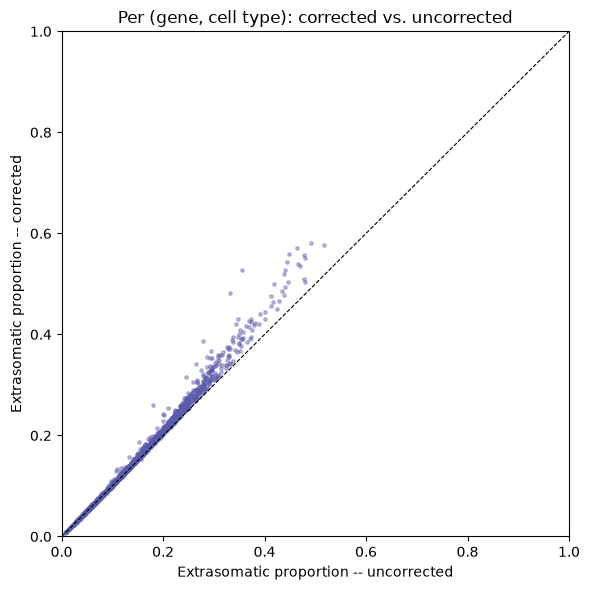

In [7]:
# Per (gene, cell_type) paired comparison
merged = pd.merge(
    df_raw[["gene", "cell_type", "extracellular_proportion"]],
    df_corr[["gene", "cell_type", "extracellular_proportion"]],
    on=["gene", "cell_type"], suffixes=("_uncorrected", "_corrected"),
)
merged.to_csv(saving_path / "extrasomatic_proportion_paired_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(merged["extracellular_proportion_uncorrected"], merged["extracellular_proportion_corrected"],
           s=6, alpha=0.4, color="#5b5bab")
lims = [0, 1]
ax.plot(lims, lims, "--", color="black", linewidth=0.8)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Extrasomatic proportion -- uncorrected")
ax.set_ylabel("Extrasomatic proportion -- corrected")
ax.set_title("Per (gene, cell type): corrected vs. uncorrected")
plt.tight_layout()
fig.savefig(saving_path / "comparison_scatter.pdf", format="pdf", bbox_inches="tight")
plt.show()

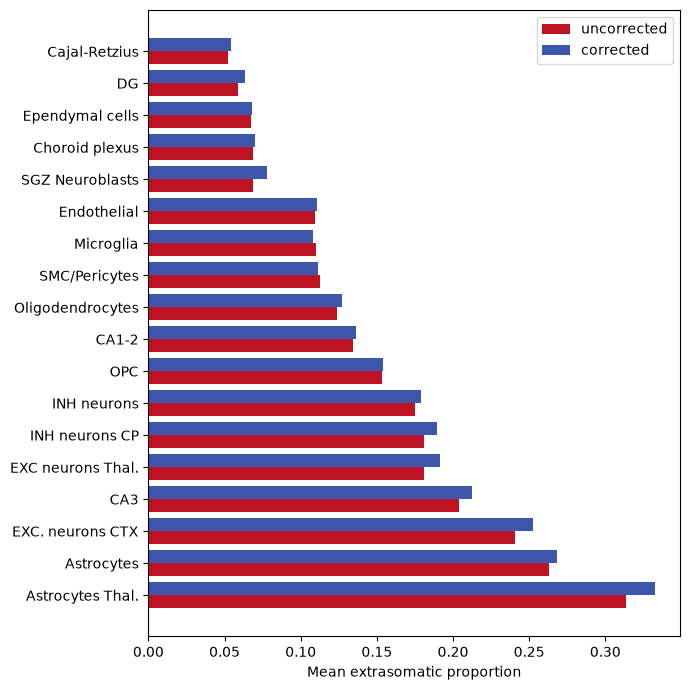

In [8]:
# Per-cell-type mean, side by side
mean_by_ct = pd.DataFrame({
    "uncorrected": df_raw.groupby("cell_type")["extracellular_proportion"].mean(),
    "corrected": df_corr.groupby("cell_type")["extracellular_proportion"].mean(),
}).dropna()
mean_by_ct = mean_by_ct.sort_values("uncorrected", ascending=False)

fig, ax = plt.subplots(figsize=(7, 7))
y = np.arange(len(mean_by_ct))
ax.barh(y - 0.2, mean_by_ct["uncorrected"], height=0.4, label="uncorrected", color="#bf1324")
ax.barh(y + 0.2, mean_by_ct["corrected"], height=0.4, label="corrected", color="#3d57ad")
ax.set_yticks(y)
ax.set_yticklabels(mean_by_ct.index)
ax.set_xlabel("Mean extrasomatic proportion")
ax.legend()
plt.tight_layout()
fig.savefig(saving_path / "comparison_mean_by_celltype_bar.pdf", format="pdf", bbox_inches="tight")
plt.show()

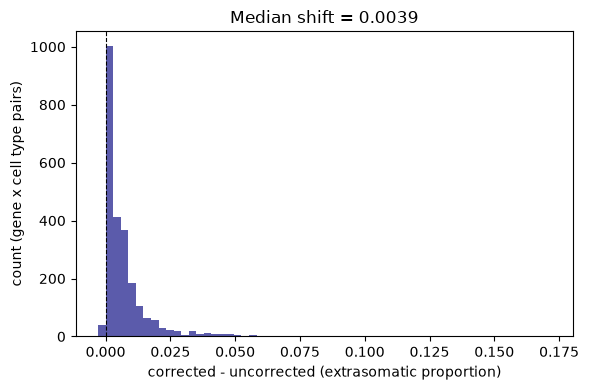

In [9]:
# Distribution of the per-(gene, cell type) shift
merged["delta"] = merged["extracellular_proportion_corrected"] - merged["extracellular_proportion_uncorrected"]

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(merged["delta"], bins=60, color="#5b5bab")
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("corrected - uncorrected (extrasomatic proportion)")
ax.set_ylabel("count (gene x cell type pairs)")
ax.set_title(f"Median shift = {merged['delta'].median():.4f}")
plt.tight_layout()
fig.savefig(saving_path / "comparison_delta_histogram.pdf", format="pdf", bbox_inches="tight")
plt.show()

## Summary

- Per-gene/cell-type tables: `extrasomatic_proportion_uncorrected.csv`, `extrasomatic_proportion_corrected.csv`, `extrasomatic_proportion_paired_comparison.csv`
- Figures (all PDF, editable text via `pdf.fonttype=42`): `violin_uncorrected.pdf`, `violin_corrected.pdf`, `comparison_scatter.pdf`, `comparison_mean_by_celltype_bar.pdf`, `comparison_delta_histogram.pdf`

All saved under `saving_path` (Lustre `ms_figures/xenium_msbrain_5k/urna_proportion_corrected_vs_uncorrected/`).